![header](dc_map_header_center.png)

# Deliverable 3: Regression Modeling and Spatial Equity Analysis

## Workflow and Key Analytical Logic

This deliverable extends the visual EDA completed in Deliverable 2 into regression modeling. The main goal is to evaluate whether roadway network conditions are associated with crash concentration across census tracts in Washington, DC, and whether these patterns overlap with higher Black and Hispanic population share tracts.

The analysis follows this workflow:

```text
1. Define the project objective and regression questions
2. Confirm the data structure and unit of analysis
3. Build a tract-level regression dataset
4. Create density, rate, and exposure-adjusted variables
5. Run Negative Binomial regression models
6. Interpret model results as tract-level spatial associations, not causation
7. Discuss limitations and possible extensions
```

The key idea is that visualization can show roadway, demographic, and crash-density patterns, but regression is needed to evaluate whether demographic variables remain associated with crash concentration after accounting for roadway exposure and traffic infrastructure.

## 1. Project Objective

The goal of this project is to examine whether roadway network conditions and roadway characteristics are associated with higher crash density across census tracts in Washington, DC, and whether these patterns disproportionately overlap with census tracts that have higher Black and Hispanic population shares.

Since insurer-level claim data is not yet available, crash density is used as a proxy outcome for auto-claim risk exposure. The analysis focuses on tract-level spatial association, not individual-level crash causation.

The two main regression questions are:

1. **After controlling for roadway exposure and traffic infrastructure, are Black and Hispanic population shares still associated with higher crash concentration?**

2. **Do high Black/Hispanic-share tracts experience higher crash concentration especially when roadway exposure is high?**

---

### Why Regression Is Needed After Visualization

The exploratory visualizations from Deliverable 2 suggest that roadway exposure variables, such as road density, signal density, and intersection density, are more clearly associated with crash density than Black or Hispanic population share alone.

However, visualization alone cannot determine whether demographic concentration is associated with crash concentration after controlling for roadway factors. Regression analysis is needed to test whether roadway exposure and demographic composition jointly explain crash patterns across census tracts.

The goal is not to prove causality. The goal is to evaluate tract-level associations and identify whether crash concentration overlaps with roadway infrastructure and demographic patterns.

---

## 2. Data Structure and Unit of Analysis

Although the source dataset is organized as a tract-month panel, many explanatory variables are static or tract-level measures, including ACS demographic estimates, roadway characteristics, and traffic infrastructure features.

Therefore, the main regression analysis aggregates the data to the census-tract level:

```text
One row = one census tract
```

The tract-level table summarizes crash outcomes over the observed 2019–2023 period and retains static tract-level attributes using the first observed value within each tract.

For descriptive comparison and feature engineering, the main crash-density outcome is:

```text
avg_annual_crash_density
```

This variable adjusts crash burden by land area and observation time:

```text
avg_annual_crash_density = total_crashes / n_years / area_km2
```

For Negative Binomial regression, the outcome variable is:

```text
total_crashes
```

Because `total_crashes` is a count outcome, the regression model includes a log exposure offset to account for differences in tract land area and observation time.

---

## 3. Tract-Level Feature Engineering

The tract-level feature engineering process includes:

```text
1. Convert GEOID to string format
2. Convert year and month to integer format
3. Create a year_month period variable
4. Fill missing traffic infrastructure count variables with 0
5. Aggregate the tract-month panel to one row per census tract
6. Sum crash-related variables across the observed period
7. Retain static tract-level attributes using the first observed value
8. Create density and rate variables
9. Create the log exposure offset for Negative Binomial regression
```

Key engineered variables include:

```text
avg_annual_crash_density
road_density_km_per_km2
signal_density_km2
intersection_density_km2
crashes_per_road_km
crashes_per_10k_pop
log_exposure_offset
```

The detailed explanation of the log exposure offset is included in the regression modeling section.

---

## 4. Regression Modeling Strategy

### 4.1 Why Negative Binomial Regression

Negative Binomial regression is used because the regression outcome is `total_crashes`, which is a count variable. Crash counts are non-negative integers and may show overdispersion, meaning the variance may be larger than the mean.

### 4.2 Traffic network counts aggregation

### 4.3 Overdispersion check

### 4.4 Log Exposure Offset

The model includes a log exposure offset:

```text
log_exposure_offset = log(area_km2 × n_years)
```

This adjusts the count model for differences in tract land area and observation time.

### 4.5 Model 1: Roadway Exposure Only

Model 1 evaluates whether roadway exposure and roadway characteristics are associated with total crash counts after adjusting for tract area and observation time.

### 4.6 Model 2: Roadway + Demographics

Model 2 adds Black and Hispanic population shares to evaluate whether these demographic variables are associated with crash concentration after controlling for roadway exposure.

### 4.7 Model 3: Interaction Model

Model 3 evaluates whether the relationship between roadway exposure and crash concentration differs across higher Black/Hispanic-share census tracts.

### 4.8 Model 4: Model 2 + additional roadway design controls

Model 2 is used as the main specification. Model 4 extends Model 2 by adding additional roadway design and exposure-related controls to assess whether these variables improve model fit and reduce unexplained residual variation.

---

## 5. Model Results and Interpretation

This section reports and interprets the regression results. The interpretation focuses on direction, magnitude, and statistical evidence, but avoids causal language.

The key interpretation framework is:

```text
IRR > 1: associated with higher expected crash counts
IRR < 1: associated with lower expected crash counts
```

All findings should be interpreted as tract-level spatial associations.

---

## 6. Limitations

This analysis has several limitations:

```text
- Crash density is used as a proxy for auto-claim risk because insurer-level claim data is not available.
- The analysis is tract-level and should not be interpreted as individual-level risk.
- Many roadway and demographic variables are static, modeled, synthetic, or ACS 5-year estimates.
- The analysis is not a time-series or causal panel design.
- Race and ethnicity variables are used as equity/disparity context variables, not causal crash-risk factors.
```

---

## 7. Conclusion

This deliverable evaluates whether roadway exposure, roadway infrastructure, and demographic composition are associated with crash concentration across census tracts in Washington, DC.

The analysis uses Negative Binomial regression to move beyond visual patterns and formally evaluate tract-level associations. The results should be interpreted as evidence of spatial association and potential equity overlap, not as proof of individual-level causation.


In [1]:
import pandas as pd
from patsy import dmatrices
import numpy as np

import statsmodels.api as sm
import statsmodels.formula.api as smf

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

## Load Dataset

In [2]:
auto_claims_dc = pd.read_csv("../../../Data/auto_claims_dc.csv")
auto_claims_dc.head(3)

,GEOID,year,month,crash_count,speeding_count,total_vehicles,fatal_driver,fatal_pedestrian,fatal_bicyclist,major_inj_driver,...,lpi_ct,ntor_ct,all_ped_phase_ct,bike_phase_ct,queue_jump_ct,tsp_ct,hawk_ct,aps_installed_ct,aps_planned_ct,ped_signal_mode_ct
0,11001000101,2019.0,1.0,2,0,4,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,11001000101,2019.0,3.0,2,0,4,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11001000101,2019.0,4.0,3,0,6,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
auto_claims_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11811 entries, 0 to 11810
Data columns (total 100 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   GEOID                          11811 non-null  int64  
 1   year                           11811 non-null  float64
 2   month                          11811 non-null  float64
 3   crash_count                    11811 non-null  int64  
 4   speeding_count                 11811 non-null  int64  
 5   total_vehicles                 11811 non-null  int64  
 6   fatal_driver                   11811 non-null  int64  
 7   fatal_pedestrian               11811 non-null  int64  
 8   fatal_bicyclist                11811 non-null  int64  
 9   major_inj_driver               11811 non-null  int64  
 10  major_inj_ped                  11811 non-null  int64  
 11  major_inj_bike                 11811 non-null  int64  
 12  weekend_crash                  11811 non-null

## 3. Tract-Level Feature Engineering

In [4]:
df = auto_claims_dc.copy()

# Convert GEOID to str type
df["GEOID"] = df["GEOID"].astype(str)

# Convert `year` and `month` column from float to int
df["year"] = df["year"].astype(int)
df["month"] = df["month"].astype(int)

# Add a new datetime variable
df["year_month"] = pd.to_datetime(
    df[["year", "month"]].assign(day=1)
).dt.to_period("M")

In [5]:
print("Earliest month:", f"{df['year_month'].min()}\n")
print("Latest month:", f"{df['year_month'].max()}\n")
df.groupby("GEOID")["year_month"].nunique().describe()

Earliest month: 2019-01

Latest month: 2023-12



count    206.000000
mean      57.334951
std        6.125472
min       16.000000
25%       57.000000
50%       60.000000
75%       60.000000
max       60.000000
Name: year_month, dtype: float64

In [6]:
# Fill missing traffic infrastructure counts with 0
# Reason: missing after spatial join often means no matched traffic signal/intersection records
traffic_cols = [
    "traffic_ct",
    "traffic_intersection_ct",
    "acisa_sum",
    "lpi_ct",
    "ntor_ct",
    "all_ped_phase_ct",
    "bike_phase_ct",
    "queue_jump_ct",
    "tsp_ct",
    "hawk_ct",
    "aps_installed_ct",
    "aps_planned_ct",
    "ped_signal_mode_ct"
]

# Safety check: `traffic_count_cols` filtering some non-existed columns
traffic_count_cols = [col for col in traffic_cols if col in df.columns]

df[traffic_count_cols] = df[traffic_count_cols].fillna(0)

1. check data time range
2. count how many observed months each tract has
3. aggregate tract-month panel to tract-level table
4. confirm whether every tract has complete monthly coverage
5. optional visual EDA of crash trends over time

Only `Crashes in DC` has datetime variable, the rest datasets are either modeled, synthetic, static roadway characteristics
- ACS 5-year demographic rolling-window estimate
- roadway block variables
- traffic signal / intersection infrastructure variables

## 4. Regression Modeling Strategy

## Demographic Variable Selection and Regression Logic

The objective of this project is to examine whether roadway conditions are associated with higher crash density across census tracts in Washington, DC, and whether these crash patterns disproportionately overlap with census tracts that have higher Black and Hispanic population shares.

The main regression questions are:

1. After controlling for roadway exposure and traffic infrastructure, are Black and Hispanic population shares still associated with higher crash concentration?

2. Do high Black/Hispanic-share census tracts experience higher crash concentration, especially when roadway exposure is high?

The full set of demographic share variables includes:

```text
white_alone_share
black_alone_share
asian_alone_share
two_or_more_races_share
other_race_share
hispanic_share
```

However, these racial and ethnic composition variables are compositional and often highly correlated with each other. For example, when the Black population share is higher in a census tract, the White population share is often lower. Similarly, when the Hispanic population share is higher, the relative shares of other groups may also change.

Including all race and ethnicity share variables in the same regression model can create several problems:

```text
- multicollinearity
- unstable coefficient estimates
- hard-to-interpret model results
```

Therefore, the main regression model focuses on `black_alone_share` and `hispanic_share`, because these variables are directly tied to the equity objective of the project. Other demographic share variables can be retained in the dataset and used later for sensitivity checks, but they are not included in the main model.

Importantly, Black and Hispanic population shares should not be interpreted as causal crash-risk factors. Instead, they are used as equity and disparity variables to examine whether crash concentration overlaps with higher Black/Hispanic-share census tracts after accounting for roadway exposure and infrastructure conditions.

### 4.1 Traffic network counts aggregation

In [7]:
tract_df = (
    df
    .groupby("GEOID", as_index=False)
    .agg(
        # Crash outcomes
        total_crashes=("crash_count", "sum"),
        avg_monthly_crashes=("crash_count", "mean"),
        total_speeding=("speeding_count", "sum"),
        total_vehicles=("total_vehicles", "sum"),
        night_crashes=("night_crash", "sum"),
        weekend_crashes=("weekend_crash", "sum"),
        rush_hour_crashes=("rush_hour_crash", "sum"),

        # Time coverage
        n_months=("year_month", "nunique"),

        # Area / population
        area_km2=("area_km2", "first"),
        total_population=("total_population", "first"),

        # Demographics
        white_alone_share=("white_alone_share", "first"),
        black_alone_share=("black_alone_share", "first"),
        asian_alone_share=("asian_alone_share", "first"),
        hispanic_share=("hispanic_share", "first"),
        two_or_more_races_share=("two_or_more_races_share", "first"),
        other_race_share=("other_race_share", "first"),

        # Traffic signal / intersection features
        traffic_ct=("traffic_ct", "first"),
        traffic_intersection_ct=("traffic_intersection_ct", "first"),
        lpi_ct=("lpi_ct", "first"),
        aps_installed_ct=("aps_installed_ct", "first"),

        # Roadway features
        road_segment_count=("road_segment_count", "first"),
        road_total_length_m=("road_total_length_m", "first"),
        mean_aadt=("mean_aadt", "first"),
        mean_iri=("mean_iri", "first"),
        mean_speedlimit_ob=("mean_speedlimit_ob", "first"),

        # Existing roadway design controls
        high_speed_ratio=("high_speed_ratio", "first"),
        bike_lane_ratio=("bike_lane_ratio", "first"),
        sidewalk_ib_ratio=("sidewalk_ib_ratio", "first"),
        sidewalk_ob_ratio=("sidewalk_ob_ratio", "first"),

        # Additional roadway design controls for Model 4
        bus_lane_ratio=("bus_lane_ratio", "first"), # bus_lane_ratio: road capacity / number of lanes
        mean_pci_score=("mean_pci_score", "first"), # mean_pci_score: pavement condition
        avg_travel_lanes=("avg_travel_lanes", "first"), # avg_travel_lanes: road capacity / number of lanes
        parking_lane_ratio=("parking_lane_ratio", "first"), # parking_lane_ratio: share of road segments with parking lane
        avg_cross_section_width=("avg_cross_section_width", "first"), # Average total street/roadway cross-section width of road segments within each census tract.
        vertical_deflection_ratio=("vertical_deflection_ratio", "first") # vertical_deflection_ratio: traffic calming features, like speed humps / raised crosswalks
    )
)

In [9]:
tract_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 36 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   GEOID                      206 non-null    object 
 1   total_crashes              206 non-null    int64  
 2   avg_monthly_crashes        206 non-null    float64
 3   total_speeding             206 non-null    int64  
 4   total_vehicles             206 non-null    int64  
 5   night_crashes              206 non-null    int64  
 6   weekend_crashes            206 non-null    int64  
 7   rush_hour_crashes          206 non-null    int64  
 8   n_months                   206 non-null    int64  
 9   area_km2                   206 non-null    float64
 10  total_population           206 non-null    int64  
 11  white_alone_share          206 non-null    float64
 12  black_alone_share          206 non-null    float64
 13  asian_alone_share          206 non-null    float64

In [42]:
import os

tract_df_dc = tract_df.copy()
data_path1 = os.path.join("..", "..", "..", "Data", "tract_df_dc.csv")

tract_df_dc.to_csv(data_path1, index=False)

### 4.2 Overdispersion check - to determine which distribution to apply

In [10]:
# Monthly crash count distribution

monthly_mean = round( auto_claims_dc["crash_count"].mean(), 4)
monthly_var = round( auto_claims_dc["crash_count"].var(), 4)
monthly_ratio = round( monthly_var / monthly_mean, 4)

print("Monthly crash_count mean:", monthly_mean)
print("Monthly crash_count variance:", monthly_var)
print("Variance / mean:", monthly_ratio)

Monthly crash_count mean: 8.8535
Monthly crash_count variance: 67.5174
Variance / mean: 7.6261


In [11]:
zero_share_monthly = (auto_claims_dc["crash_count"] == 0).mean()

print("Share of tract-month observations with 0 crashes:", zero_share_monthly)

Share of tract-month observations with 0 crashes: 0.0


In [12]:
auto_claims_dc["crash_count"].min()

1

The Crashes in DC dataset is a public mapped crash-record dataset derived from MPD crash records and processed by DDOT. Therefore, the tract-month table constructed from this dataset contains tract-months with at least one mapped crash record, rather than a complete balanced panel with explicit zero-crash months.

In the current tract-month table, the minimum crash count is 1, meaning that zero-crash tract-months are not explicitly represented. Missing tract-month combinations may represent months with no recorded crashes, but they could also reflect unmapped or filtered crash records due to data quality or geocoding limitations.

For the tract-level regression, missing zero-crash months do not affect total crash counts because adding zero would not change the total. However, the number of months present in the table should not be interpreted as the observation period. The regression therefore treats all census tracts as observed over the full 2019–2023 study window and uses a five-year exposure period in the log offset.

This model uses the currently available tract-month records. The exposure period is based on the number of months present in the current crash-positive tract-month table, rather than a fully balanced 2019–2023 tract-month panel.

In [13]:
tract_mean = (tract_df["total_crashes"] == 0).mean()

tract_var = (tract_df["total_crashes"] == 0).var()

tract_ratio = tract_var / tract_mean

print("tract_mean", tract_mean)
print("tract_var", tract_var)
print("tract_ratio", tract_ratio)

tract_mean 0.0
tract_var 0.0
tract_ratio nan


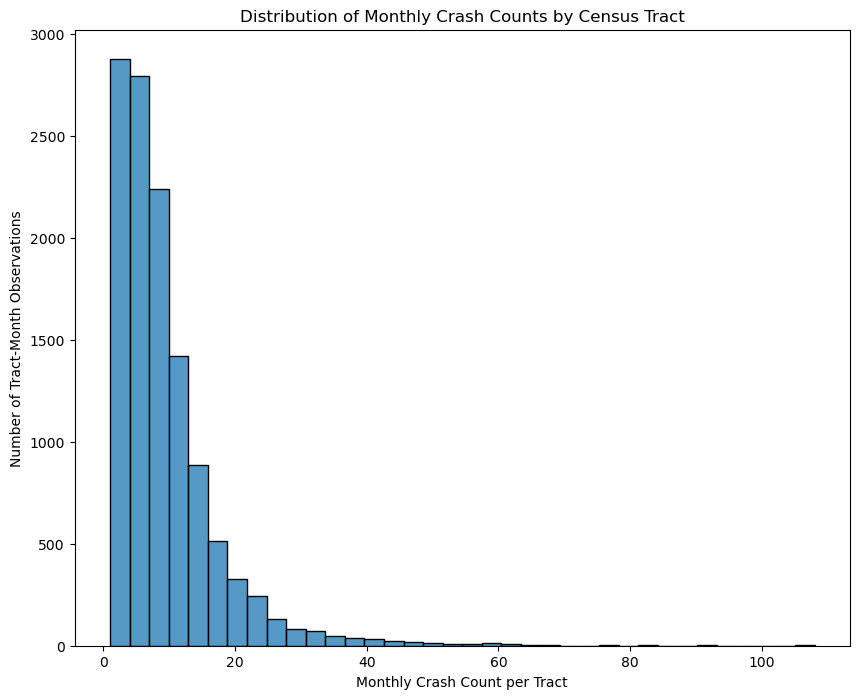

In [14]:
# Crash count distribution

import seaborn as sns

plt.figure(figsize=(10, 8))

sns.histplot(
    data=auto_claims_dc,
    x="crash_count",
    binwidth=3
)

plt.title("Distribution of Monthly Crash Counts by Census Tract")
plt.xlabel("Monthly Crash Count per Tract")
plt.ylabel("Number of Tract-Month Observations")

plt.show()

Variance / Mean is quite significant, this indicates overdispersion exists. 

most tract-month observations have low crash counts

a small number of tract-month observations have very high crash counts

negative binomial regression

### 4.3 Log Exposure Offset

#### Log Exposure Offset in the Negative Binomial Model

For the Negative Binomial regression, the outcome variable is:

```text
total_crashes
```

This is a count outcome. Count outcomes have several important characteristics:

```text
- They can only take non-negative integer values: 0, 1, 2, 3, ...
- They cannot be negative.
- They are not continuous variables.
- Their variance is often larger than their mean, which is known as overdispersion.
```

Because crash counts are non-negative count data and may be overdispersed, Negative Binomial regression is more appropriate than ordinary linear regression for modeling total crash counts.

A regular linear regression model has the form:

```text
Y = β0 + β1X1 + β2X2 + ...
```

However, this type of model can produce negative predicted crash counts, such as:

```text
predicted crashes = -12.5
```

This is not meaningful because crash counts cannot be negative. Negative Binomial regression avoids this problem by using a log link function.

Importantly, the model does **not** directly transform the observed outcome using:

```text
log(total_crashes)
```

Instead, the model applies the log link to the expected crash count:

```text
log(expected total_crashes) = predictors + offset
```

In model notation:

```text
Y_i = observed total_crashes for census tract i
μ_i = expected total_crashes for census tract i
```

The Negative Binomial model assumes:

```text
Y_i ~ Negative Binomial(μ_i)
```

and uses the following log-link structure:

```text
log(μ_i) = β0 + β1X1_i + β2X2_i + ... + βkXk_i + log(exposure_i)
```

The log link is useful because exponentiating the linear predictor guarantees that the expected crash count is always positive:

```text
μ_i = exp(β0 + β1X1_i + β2X2_i + ...)
```

Since `exp(...)` is always positive, the model will not predict negative expected crash counts.

---

#### Exposure and Offset

Because `total_crashes` is a raw count, the model also needs to account for the fact that census tracts differ in land area and observation time. A larger tract or a tract observed for more months has more exposure opportunity for crashes.

In this project, exposure is defined as:

```text
exposure_i = area_km2_i × n_years_i
```

where:

```text
n_years_i = n_months_i / 12
```

This exposure term represents the amount of spatial and temporal exposure for each census tract. Its unit can be understood as:

```text
km²-years
```

Because the project focuses on crash density and spatial crash concentration, this exposure definition is appropriate. It allows the model to compare crash counts relative to land area and observation time.

The offset is defined as:

```text
log_exposure_offset = log(area_km2 × n_years)
```

This is not a regular predictor. An offset is a known exposure adjustment added to the model with its coefficient fixed at 1. It is not estimated like other regression coefficients.

The goal is to model the expected crash rate:

```text
expected crash rate = expected total_crashes / exposure
```

Using notation:

```text
expected crash rate_i = μ_i / exposure_i
```

We allow this expected crash rate to be explained by the predictors:

```text
μ_i / exposure_i = exp(β0 + β1X1_i + β2X2_i + ... + βkXk_i)
```

Multiplying both sides by exposure gives:

```text
μ_i = exposure_i × exp(β0 + β1X1_i + β2X2_i + ... + βkXk_i)
```

Taking the log of both sides gives:

```text
log(μ_i) = log(exposure_i) + β0 + β1X1_i + β2X2_i + ... + βkXk_i
```

Therefore, the offset enters the model as:

```text
log(exposure_i)
```

In this project:

```text
log(exposure_i) = log(area_km2_i × n_years_i)
```

---

#### Interpretation

The Negative Binomial model can be written as:

```text
log(expected total_crashes_i)
= β0 + β1X1_i + β2X2_i + ... + βkXk_i + log(area_km2_i × n_years_i)
```

Equivalently:

```text
expected total_crashes_i = exposure_i × exp(predictors_i)
```

where:

```text
exposure_i = area_km2_i × n_years_i
```

This means the model estimates crash risk relative to the amount of spatial and temporal exposure, rather than simply comparing raw crash counts.

For example:

```text
Tract A: 500 crashes / 1 km² / 5 years = 100 crashes per km² per year
Tract B: 500 crashes / 3 km² / 5 years = 33.3 crashes per km² per year
```

Although both tracts have the same raw crash count, Tract B has a larger land area. Therefore, the same number of crashes represents a lower crash rate per km² per year in Tract B.

The offset allows the Negative Binomial model to account for this difference in exposure. It helps compare crash counts fairly across census tracts with different land areas and different numbers of observed months.

In short, the model still uses `total_crashes` as the outcome, but the offset adjusts the model so that the estimated relationships are closer to crash rates per km² per year rather than raw crash totals.


In [15]:
# Step 6: Create density and rate variables

# Tract-specific observed years
tract_df["n_years"] = tract_df["n_months"] / 12

# Road length in km
tract_df["road_length_km"] = tract_df["road_total_length_m"] / 1000

# Cumulative crash density over full observed period
tract_df["crash_density_km2"] = (
    tract_df["total_crashes"] / tract_df["area_km2"]
)

# Average annual crash density
tract_df["avg_annual_crash_density"] = (
    tract_df["total_crashes"] / tract_df["n_years"] / tract_df["area_km2"]
)

# Crashes per road km
tract_df["crashes_per_road_km"] = (
    tract_df["total_crashes"] / tract_df["road_length_km"]
)

# Crashes per 10K population
tract_df["crashes_per_10k_pop"] = (
    tract_df["total_crashes"] / tract_df["total_population"] * 10000
)

# Road density
tract_df["road_density_km_per_km2"] = (
    tract_df["road_length_km"] / tract_df["area_km2"]
)

# Road segment density
tract_df["road_segment_density_km2"] = (
    tract_df["road_segment_count"] / tract_df["area_km2"]
)

# Traffic signal density
tract_df["signal_density_km2"] = (
    tract_df["traffic_ct"] / tract_df["area_km2"]
)

# Traffic intersection density
tract_df["intersection_density_km2"] = (
    tract_df["traffic_intersection_ct"] / tract_df["area_km2"]
)

# tract_df["n_months"] = 60
# tract_df["n_years"] = 5

# Negative Binomial exposure offset
tract_df["log_exposure_offset"] = np.log(
    tract_df["area_km2"] * tract_df["n_years"]
)

### 4.4 Model readiness check

In [16]:
model_cols = [
    "total_crashes",
    "area_km2",
    "n_years",
    "log_exposure_offset",
    "road_density_km_per_km2",
    "signal_density_km2",
    "intersection_density_km2",
    "mean_aadt",
    "mean_iri",
    "mean_speedlimit_ob",
    "black_alone_share",
    "hispanic_share"
]

In [17]:
tract_df[model_cols].isna().sum()

total_crashes               0
area_km2                    0
n_years                     0
log_exposure_offset         0
road_density_km_per_km2     0
signal_density_km2          0
intersection_density_km2    0
mean_aadt                   0
mean_iri                    0
mean_speedlimit_ob          0
black_alone_share           0
hispanic_share              0
dtype: int64

In [18]:
np.isinf(tract_df[model_cols]).sum()

total_crashes               0
area_km2                    0
n_years                     0
log_exposure_offset         0
road_density_km_per_km2     0
signal_density_km2          0
intersection_density_km2    0
mean_aadt                   0
mean_iri                    0
mean_speedlimit_ob          0
black_alone_share           0
hispanic_share              0
dtype: int64

In [19]:
tract_df[model_cols].describe()

,total_crashes,area_km2,n_years,log_exposure_offset,road_density_km_per_km2,signal_density_km2,intersection_density_km2,mean_aadt,mean_iri,mean_speedlimit_ob,black_alone_share,hispanic_share
count,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000
mean,507.616505,0.768525,4.777913,0.929290,27.058969,15.498257,15.225024,11325.116429,293.421841,21.742244,0.417389,0.110329
std,424.006113,0.855192,0.510456,0.850222,10.630777,15.020839,14.769801,9446.722902,64.256980,1.028976,0.329904,0.085446
min,19.000000,0.093419,1.333333,-1.172745,10.666265,0.000000,0.000000,2538.200000,109.000000,19.852941,0.000000,0.000000
25%,224.250000,0.290739,4.750000,0.286841,20.021127,4.629223,4.629223,7567.067308,249.442503,21.020588,0.111155,0.052492
50%,411.500000,0.507151,5.000000,0.920468,25.823145,9.778569,9.470704,9630.482759,290.655985,21.585317,0.327836,0.091850
75%,611.750000,0.907396,5.000000,1.489927,31.937454,23.546794,23.434401,12534.495455,328.648910,22.368421,0.734928,0.148162
max,2984.000000,6.514228,5.000000,3.483427,94.543675,74.931224,74.931224,113241.000000,658.000000,25.102041,0.986292,0.460513


## Negative Binomial Regression Results Interpretation

The three Negative Binomial regression models estimate associations with `total_crashes` at the census-tract level. Because this is a count model with a log link, the coefficients should be interpreted on the log expected crash-count scale.

The general model structure is:

```text
log(expected total_crashes) = β0 + β1X1 + β2X2 + ... + log_exposure_offset
```

Therefore, a positive coefficient means the variable is associated with higher expected crash counts, holding other variables constant. The coefficients are not interpreted as direct raw increases in crash counts.

Model 1: Roadway exposure baseline

Model 2: Roadway + Black/Hispanic share  ← main model

Model 3: Interaction model (roadway exposure × Black/Hispanic share)

Model 4: Model 2 + roadway design controls

Model 5: Model 4 + land use / zoning controls

### Model 1: Roadway baseline

In [25]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# ---------------------------------------------------------
# Model 1: Roadway baseline model
# Outcome: crash count
# Predictors: roadway exposure + traffic/condition controls
# Offset: log land-area exposure
# ---------------------------------------------------------

# Use total_crashes if it exists, otherwise use crash_count
outcome_col = "total_crashes" if "total_crashes" in tract_df.columns else "crash_count"

# Ensure n_years exists
if "n_years" not in tract_df.columns:
    tract_df["n_years"] = tract_df["n_months"] / 12
    
# Create log exposure offset if it does not already exist
# For tract-month panel, the main exposure adjustment is land area
# If you later aggregate to tract-level over multiple years/months
# Use log(area_km2 * observed_time) instead
if "log_exposure_offset" not in tract_df.columns:
    tract_df["log_exposure_offset"] = np.log(
        (tract_df["area_km2"] * tract_df["n_years"]).clip(lower=1e-6)
    )

# Model 1 predictors
model1_vars = [
    "road_density_km_per_km2",
    "signal_density_km2",
    "intersection_density_km2",
    "mean_aadt",
    "mean_iri",
    "mean_speedlimit_ob"
]

# Keep only needed columns and drop missing values
required_cols = [outcome_col, "log_exposure_offset", "GEOID"] + model1_vars

model1_df = (
    tract_df[required_cols]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

# Build formula
model1_formula = f"""
{outcome_col} ~
road_density_km_per_km2
+ signal_density_km2
+ intersection_density_km2
+ mean_aadt
+ mean_iri
+ mean_speedlimit_ob
"""

# Fit Negative Binomial GLM
nb_model1 = smf.glm(
    formula=model1_formula,
    data=model1_df,
    family=sm.families.NegativeBinomial(),
    offset=model1_df["log_exposure_offset"]
).fit(cov_type="HC3")

# HC3 adjusts the standard errors to make statistical inference more robust to heteroskedasticity and influential observations. This can change the z-statistics, p-values, and confidence intervals, but it does not change the estimated coefficients or model fit statistics.

# Works with panel data
# cov_type="cluster",
#     cov_kwds={"groups": model1_df["GEOID"]}

print(nb_model1.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          total_crashes   No. Observations:                  206
Model:                            GLM   Df Residuals:                      199
Model Family:        NegativeBinomial   Df Model:                            6
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1465.1
Date:                Sat, 27 Jun 2026   Deviance:                       72.648
Time:                        12:47:04   Pearson chi2:                     68.3
No. Iterations:                     9   Pseudo R-squ. (CS):             0.2309
Covariance Type:                  HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

## Model 1: Roadway Exposure Baseline Model

### Significant Variable at the 5% Level

```text
road_density_km_per_km2: p < 0.001
mean_aadt: p = 0.005
mean_iri: p = 0.041
mean_speedlimit_ob: p = 0.039
```

### Marginal Significant at the 10% Level

```text
signal_density_km2: p = 0.084
```

### Not Significant

```text
intersection_density_km2: p = 0.156
```

### Interpretation

Model 1 serves as the roadway baseline model. It includes roadway exposure and roadway-condition variables only, without demographic variables. The purpose of this model is to evaluate whether roadway network characteristics are associated with total crash counts before adding demographic context.

Using HC3 robust standard errors, `road_density_km_per_km2`, `mean_aadt`, `mean_iri`, and `mean_speedlimit_ob` are positively and statistically significantly associated with total crash counts at the 5% level.

The model can be interpreted conceptually as:

```text
log(expected total_crashes)
= β0
+ 0.0284 × road_density_km_per_km2
+ 0.1026 × signal_density_km2
- 0.0859 × intersection_density_km2
+ 8.683e-06 × mean_aadt
+ 0.0011 × mean_iri
+ 0.0796 × mean_speedlimit_ob
+ 1 x log_exposure_offset
```

Because this is a Negative Binomial GLM with a log-link terms, the coefficients represent changes in the log of expected crash counts, holding the other roadway variables and exposure offset constant.

The positive coefficient for `road_density_km_per_km2` suggests that census tracts with denser roadway networks tend to have higher expected crash counts. In percentage terms, while holding all other variables constant, a one-unit increase in road density is associated with approximately a 2.9% increase in expected crash counts.

`mean_aadt`, `mean_iri`, and `mean_speedlimit_ob` are also positive and statistically significant. This suggests that tracts with higher average traffic volume, rougher roadway conditions, and higher speed-limit environments tend to have higher expected crash counts, after adjusting for roadway exposure and land-area/time exposure.

`signal_density_km2` is positive but only marginally significant at the 10% level. This suggests weaker evidence that signal density is associated with higher expected crash counts in the baseline model.

`intersection_density_km2` has a negative coefficient but is not statistically significant. Therefore, this model does not provide strong evidence that intersection density has an independent association with expected crash counts after accounting for road density, signal density, AADT, IRI, and speed-limit environment.

Overall, Model 1 suggests that roadway network density, traffic volume, roadway condition, and speed environment are important baseline roadway factors associated with crash concentration. This provides the foundation for Model 2, where demographic context variables are added to evaluate whether the roadway-exposure findings remain stable after accounting for Black and Hispanic population share.

### Why is the coefficient for the offset fixed at 1?

The log exposure offset adjusts for differences in census tract area and observation time. It is included as an offset rather than as an estimated predictor, so its coefficient is fixed at 1 by definition. As a result, it does not appear in the regression coefficient table.

In other words, the model assumes that expected crash counts scale proportionally with the amount of exposure, measured as land area multiplied by observed time.

### Why is the log exposure offset needed?

The dependent variable in this model is `total_crashes`, which represents the cumulative number of crashes from 2019 to 2023. Because this is a multi-year crash count, raw crash totals are not directly comparable across census tracts.

Different census tracts vary in land area, and some tracts may have slightly different observed time coverage. A larger tract, or a tract observed for a longer period, naturally has more opportunity for crashes to occur.

Therefore, the offset is defined as:

```text
log_exposure_offset = log(area_km2 × n_years)
```

This tells the model how much space and time each census tract was exposed to crash risk. By including this offset, the Negative Binomial model estimates expected crash counts relative to area-time exposure, rather than comparing raw crash totals alone.

### Model 2: Roadway + Black/Hispanic share ← main model

In [27]:
nb_model2 = smf.glm(
    formula="""
    total_crashes ~
    road_density_km_per_km2
    + signal_density_km2
    + intersection_density_km2
    
    + mean_aadt
    + mean_iri
    + mean_speedlimit_ob
    
    + black_alone_share
    + hispanic_share
    """,
    data=tract_df,
    family=sm.families.NegativeBinomial(),
    offset=tract_df["log_exposure_offset"]
).fit(cov_type="HC3")

print(nb_model2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          total_crashes   No. Observations:                  206
Model:                            GLM   Df Residuals:                      197
Model Family:        NegativeBinomial   Df Model:                            8
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1457.1
Date:                Sat, 27 Jun 2026   Deviance:                       56.625
Time:                        13:20:43   Pearson chi2:                     63.9
No. Iterations:                    10   Pseudo R-squ. (CS):             0.2884
Covariance Type:                  HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

## Model 2: Roadway Exposure + Black/Hispanic Population Share

### Significant Variables at the 5% Level

```text
road_density_km_per_km2: p < 0.001
mean_speedlimit_ob: p = 0.029
black_alone_share: p < 0.001
```

### Marginally Significant Variables at the 10% Level

```text
signal_density_km2: p = 0.073
mean_aadt: p = 0.067
mean_iri: p = 0.089
```

### Variables Not Statistically Significant

```text
intersection_density_km2: p = 0.156
hispanic_share: p = 0.314
```

### Interpretation

Model 2 adds Black and Hispanic population share to the roadway exposure model. Using HC3 robust standard errors, `road_density_km_per_km2`, `mean_speedlimit_ob`, and `black_alone_share` are positively and statistically significantly associated with total crash counts at the 5% level.

The model can be interpreted conceptually as:

```text
log(expected total_crashes)
= β0
+ 0.0313 × road_density_km_per_km2
+ 0.1412 × signal_density_km2
- 0.1132 × intersection_density_km2
+ 4.24e-06 × mean_aadt
+ 0.0010 × mean_iri
+ 0.0765 × mean_speedlimit_ob
+ 1.0493 × black_alone_share
+ 0.4857 × hispanic_share
+ log_exposure_offset
```

This suggests that census tracts with higher road density, higher speed-limit environment, and higher Black population share tend to have higher expected crash counts, after adjusting for land-area/time exposure and other roadway characteristics.

`signal_density_km2`, `mean_aadt`, and `mean_iri` are not statistically significant at the 5% level under HC3 robust standard errors, but they show marginal evidence at the 10% level. This means they may still be relevant roadway context variables, but the statistical evidence is weaker.

`intersection_density_km2` has a negative coefficient, but it is not statistically significant. Therefore, this model does not provide strong evidence that intersection density has an independent association with expected crash counts after accounting for road density, signal density, and other controls.

`hispanic_share` is not statistically significant in this model, meaning the model does not provide strong statistical evidence that Hispanic population share is independently associated with total crash counts after accounting for roadway exposure and other roadway characteristics.

Importantly, `black_alone_share` should not be interpreted as a causal crash-risk factor. It should be interpreted as a tract-level equity and spatial context variable that helps evaluate whether crash concentration overlaps with higher Black-share census tracts.


## Model 2: Roadway Exposure + Black/Hispanic Population Share

### Significant Variables at the 5% Level

```text
road_density_km_per_km2: p < 0.001
mean_speedlimit_ob: p = 0.029
black_alone_share: p < 0.001
```

### Marginally Significant Variables at the 10% Level

```text
signal_density_km2: p = 0.073
mean_aadt: p = 0.067
mean_iri: p = 0.089
```

### Variables Not Statistically Significant

```text
intersection_density_km2: p = 0.156
hispanic_share: p = 0.314
```

### Interpretation

Model 2 extends the roadway baseline model by adding Black and Hispanic population share as tract-level demographic context variables. The purpose of this model is to evaluate whether roadway exposure remains associated with crash concentration after accounting for demographic context, and whether crash concentration overlaps with higher Black-share or Hispanic-share census tracts.

Using HC3 robust standard errors, `road_density_km_per_km2`, `mean_speedlimit_ob`, and `black_alone_share` are positively and statistically significantly associated with total crash counts at the 5% level.

Because this is a Negative Binomial GLM with a log link, the coefficients represent changes in the log of expected crash counts. In practical terms, positive coefficients indicate higher expected crash counts, holding the other variables and the exposure offset constant.

The model can be interpreted conceptually as:

```text
log(expected total_crashes)
= β0
+ roadway exposure variables
+ roadway condition / traffic controls
+ Black and Hispanic population share
+ log_exposure_offset
```

The positive and significant coefficient for `road_density_km_per_km2` suggests that census tracts with denser roadway networks tend to have higher expected crash counts, after adjusting for land-area/time exposure and other roadway characteristics.

The positive and significant coefficient for `mean_speedlimit_ob` suggests that census tracts with higher average speed-limit environments are associated with higher expected crash counts, holding other variables constant.

The positive and significant coefficient for `black_alone_share` suggests that census tracts with higher Black population share are associated with higher expected crash counts, even after accounting for roadway exposure, traffic volume, roadway condition, speed environment, and the exposure offset.

However, this result should not be interpreted as a causal demographic effect. `black_alone_share` should be interpreted as a tract-level spatial equity context variable. The result suggests that crash concentration overlaps with higher Black-share census tracts, but it does not mean that Black population share itself causes crashes.

`signal_density_km2`, `mean_aadt`, and `mean_iri` are not statistically significant at the 5% level under HC3 robust standard errors, but they show marginal evidence at the 10% level. This means they may still be relevant roadway context variables, but the evidence for their independent association is weaker.

`intersection_density_km2` is not statistically significant. Although it is included as a roadway exposure control, the model does not provide strong evidence that intersection density has an independent association with expected crash counts after accounting for road density, signal density, and other roadway controls.

`hispanic_share` is also not statistically significant in this model. Therefore, Model 2 does not provide strong statistical evidence that Hispanic population share is independently associated with total crash counts after accounting for roadway exposure and other roadway characteristics.

Overall, Model 2 suggests that roadway density, speed environment, and Black population share are the strongest statistically significant predictors in the main model. The findings support the project’s central interpretation that crash concentration is associated with both roadway exposure and tract-level spatial equity context.

## Model 3: Interaction model

### Why Standardization and Centering Were Used in Model 3

Model 3 uses a roadway exposure index that combines road density, signal density, and intersection density. Because these variables are measured in different units and have different numerical ranges, they were standardized before being combined. This ensures that each component contributes more comparably to the index, rather than allowing one variable to dominate simply because it has larger values.

Black and Hispanic population shares were mean-centered before creating interaction terms. After centering, a value of zero represents the average demographic share across DC census tracts, rather than a tract with 0% Black or Hispanic population. This makes the interaction model easier to interpret.

For example, the main effect of roadway exposure can be interpreted as the association between roadway exposure and expected crash counts at the average Black and Hispanic population share. Similarly, the main effect of Black population share can be interpreted at the average roadway exposure level.

In [21]:
# Create roadway exposure index if needed
# This combines major roadway exposure variables into one standardized index

# Step 1: standardize roadway exposure components
exposure_cols = [
    "road_density_km_per_km2",
    "signal_density_km2",
    "intersection_density_km2"
]

"""
Standardizes a dataset (Z-score normalization).
Transforms data so that Mean = 0 and Standard Deviation = 1.

Formula: z = (x - mean) / std_dev
"""
for col in exposure_cols:
    tract_df[f"z_{col}"] = (
        tract_df[col] - tract_df[col].mean()
    ) / tract_df[col].std()

# Step 2: Create roadway exposure index
tract_df["roadway_exposure_index"] = tract_df[
    [f"z_{col}" for col in exposure_cols]
].mean(axis=1)

# Step 3: Center demographic share variables
tract_df["black_alone_share_c"] = (
    tract_df["black_alone_share"] - tract_df["black_alone_share"].mean()
)

tract_df["hispanic_share_c"] = (
    tract_df["hispanic_share"] - tract_df["hispanic_share"].mean()
)

In [22]:
# Step 4: Run model3 interaction model
nb_model3 = smf.glm(
    formula="""
    total_crashes ~
    roadway_exposure_index * black_alone_share_c
    + roadway_exposure_index * hispanic_share_c
    + mean_aadt
    + mean_iri
    + mean_speedlimit_ob
    """,
    data=tract_df,
    family=sm.families.NegativeBinomial(),
    offset=tract_df["log_exposure_offset"]
).fit(cov_type="HC3")

print(nb_model3.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          total_crashes   No. Observations:                  206
Model:                            GLM   Df Residuals:                      197
Model Family:        NegativeBinomial   Df Model:                            8
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1459.0
Date:                Fri, 26 Jun 2026   Deviance:                       60.385
Time:                        22:37:27   Pearson chi2:                     86.8
No. Iterations:                     9   Pseudo R-squ. (CS):             0.2753
Covariance Type:                  HC3                                         
                                                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

## Model 3: Roadway Exposure Interaction Model

Model 3 tests whether the relationship between roadway exposure and expected crash counts differs by Black or Hispanic population share. Instead of including separate roadway exposure variables, the model uses a standardized roadway exposure index based on road density, signal density, and intersection density.

The overall roadway exposure index is positively and statistically significantly associated with expected crash counts. Black population share is also positively and statistically significantly associated with expected crash counts at the census-tract level.

However, the interaction terms are not statistically significant. This means the model does not provide strong evidence that the effect of roadway exposure is amplified in higher Black-share or higher Hispanic-share census tracts.

In other words, roadway exposure and Black population share are separately associated with higher expected crash counts, but the model does not show strong evidence that roadway exposure has a stronger effect specifically in higher Black-share or higher Hispanic-share areas.

Model 3 has a pseudo R-squared of 0.2753, which is slightly lower than Model 2. Therefore, Model 3 is best interpreted as an interaction check rather than the main model. The main interpretation remains based on Model 2.


## Model 4: Model 2 + roadway design controls

In [43]:
tract_df[["vertical_deflection_ratio", "mean_aadt"]].corr()

,vertical_deflection_ratio,mean_aadt
vertical_deflection_ratio,1.000000,-0.038911
mean_aadt,-0.038911,1.000000


vertical_deflection_ratio does not show a strong linear correlation with mean_aadt at the census-tract level.

In [23]:
# Model 4 predictors
model4_vars = [
    "road_density_km_per_km2",
    "signal_density_km2",
    "intersection_density_km2",
    
    "mean_aadt",
    "mean_iri",
    "mean_speedlimit_ob",
    
    "black_alone_share",
    "hispanic_share",
    
    "avg_travel_lanes",
    "avg_cross_section_width",
    "bike_lane_ratio",
    "bus_lane_ratio",
    "parking_lane_ratio",
    "sidewalk_ib_ratio",
    "sidewalk_ob_ratio",
    "high_speed_ratio",
    "vertical_deflection_ratio",
    "mean_pci_score"
]

missing_vars = [var for var in model4_vars if var not in tract_df.columns]

if missing_vars:
    raise ValueError(f"These Model 4 variables are missing from tract_df: {missing_vars}")

model4_df = (
    tract_df[["total_crashes", "log_exposure_offset"] + model4_vars]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

# Build formula
model4_formula = f"""
{outcome_col} ~
road_density_km_per_km2
+ signal_density_km2
+ intersection_density_km2

+ mean_aadt
+ mean_iri
+ mean_speedlimit_ob

+ black_alone_share
+ hispanic_share

+ avg_travel_lanes
+ avg_cross_section_width
+ bike_lane_ratio
+ bus_lane_ratio
+ parking_lane_ratio
+ sidewalk_ib_ratio
+ sidewalk_ob_ratio
+ high_speed_ratio
+ vertical_deflection_ratio
+ mean_pci_score
"""

# Fit Negative Binomial GLM w/ HC3 robust standard errors
nb_model4 = smf.glm(
    formula=model4_formula,
    data=model4_df,
    family=sm.families.NegativeBinomial(),
    offset=model4_df["log_exposure_offset"]
).fit(cov_type="HC3")

print(nb_model4.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          total_crashes   No. Observations:                  206
Model:                            GLM   Df Residuals:                      187
Model Family:        NegativeBinomial   Df Model:                           18
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1446.1
Date:                Fri, 26 Jun 2026   Deviance:                       34.649
Time:                        23:12:53   Pearson chi2:                     34.4
No. Iterations:                     9   Pseudo R-squ. (CS):             0.3604
Covariance Type:                  HC3                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

## Model 4: Model 2 + Roadway Design Controls

### Purpose

Model 4 extends Model 2 by adding additional roadway design controls. These controls include roadway capacity, street width, bike and bus lane coverage, parking lane coverage, sidewalk coverage, high-speed roadway share, vertical deflection traffic-calming features, and pavement condition.

The purpose of Model 4 is not to replace Model 2 as the main model. Instead, Model 4 is used as a robustness check to evaluate whether the main Model 2 findings remain stable after accounting for more detailed roadway design characteristics.

### Additional Roadway Design Controls Added in Model 4

```text
avg_travel_lanes
avg_cross_section_width
bike_lane_ratio
bus_lane_ratio
parking_lane_ratio
sidewalk_ib_ratio
sidewalk_ob_ratio
high_speed_ratio
vertical_deflection_ratio
mean_pci_score
```

### Interpretation

Model 4 adds more detailed roadway design variables to the main Model 2 specification. These variables capture additional characteristics of the roadway environment, including road capacity, street width, multimodal infrastructure, sidewalk coverage, speed-related design, traffic-calming features, and pavement condition.

The model can be interpreted conceptually as:

```text
log(expected total_crashes)
= β0
+ roadway exposure variables
+ roadway traffic / condition controls
+ Black and Hispanic population share
+ additional roadway design controls
+ log_exposure_offset
```

Compared with Model 2, Model 4 tests whether the association between crash counts, roadway exposure, and demographic context remains stable after controlling for a broader set of roadway design features.

If `road_density_km_per_km2` remains positive and statistically significant in Model 4, this suggests that the relationship between roadway density and expected crash counts is robust to the inclusion of additional roadway design controls.

If `black_alone_share` remains positive and statistically significant in Model 4, this suggests that the tract-level association between Black population share and expected crash counts is also robust after accounting for more detailed roadway design characteristics.

If `hispanic_share` remains not statistically significant, this is consistent with Model 2 and suggests that the model does not provide strong evidence of an independent association between Hispanic population share and expected crash counts.

Model 4 may improve pseudo R-squared compared with Model 2 because it includes more predictors and captures more roadway design variation. However, this improvement should be interpreted as better in-sample fit, not necessarily as evidence that Model 4 is the best model. Because Model 4 is more complex and includes many additional predictors, it should be treated as a robustness check rather than the primary model.

Overall, Model 4 is used to evaluate coefficient stability. If the main Model 2 findings remain similar after adding roadway design controls, then the project’s core conclusion is strengthened: crash concentration is associated with roadway exposure and tract-level spatial equity context, particularly higher Black population share, even after accounting for additional roadway design characteristics.


## Model 4 Additional Roadway Design Predictors

Model 4 adds additional roadway design and infrastructure controls to evaluate whether the main Model 2 findings remain stable after accounting for more detailed roadway characteristics. These predictors capture roadway capacity, physical width, multimodal infrastructure, curbside design, speed environment, traffic-calming features, and pavement condition.

| Predictor                   | Indicator Type                      | Interpretation                                                                                                                                                                   |
| --------------------------- | ----------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `avg_travel_lanes`          | Roadway capacity                    | Average number of travel lanes within a census tract. Higher values generally indicate greater roadway capacity and may reflect the presence of wider or more major roads.       |
| `avg_cross_section_width`   | Roadway physical width              | Average roadway cross-section width within a census tract. This captures the overall physical width of road segments, including travel lanes and other roadway space.            |
| `bike_lane_ratio`           | Bicycle infrastructure coverage     | Share of roadway segments with bike lanes. Higher values indicate greater bicycle infrastructure coverage.                                                                       |
| `bus_lane_ratio`            | Bus/transit infrastructure coverage | Share of roadway segments with bus lanes or bus-priority infrastructure. Higher values indicate greater transit-oriented roadway infrastructure.                                 |
| `parking_lane_ratio`        | Curbside parking coverage           | Share of roadway segments with parking lanes. This captures the presence of curbside parking, which may be related to residential, commercial, or mixed-use street environments. |
| `sidewalk_ib_ratio`         | Sidewalk coverage                   | Share of roadway segments with sidewalk coverage on one side or direction of the roadway. This captures pedestrian infrastructure availability.                                  |
| `sidewalk_ob_ratio`         | Sidewalk coverage                   | Share of roadway segments with sidewalk coverage on the opposite side or direction of the roadway. This also captures pedestrian infrastructure availability.                    |
| `high_speed_ratio`          | High-speed roadway exposure         | Share of roadway segments classified as higher-speed roads. Higher values indicate a greater presence of high-speed roadway environments within the tract.                       |
| `vertical_deflection_ratio` | Traffic-calming infrastructure      | Share of roadway segments with vertical deflection traffic-calming features, such as speed humps, speed bumps, raised crosswalks, or speed tables.                               |
| `mean_pci_score`            | Pavement condition                  | Average Pavement Condition Index score. Higher PCI values generally indicate better pavement condition, while lower values indicate poorer pavement condition.                   |

Overall, these variables allow Model 4 to control for a broader set of roadway design characteristics beyond the baseline roadway exposure variables. The purpose is to test whether the associations found in Model 2, especially for road density and Black population share, remain stable after accounting for additional infrastructure and roadway-condition factors.


## Comparison Between Model 2 and Model 4

Model 2 is the main model because it directly addresses the project’s central question: whether roadway exposure and tract-level demographic context are associated with expected crash counts.

Model 4 adds additional roadway design controls as a robustness check. The goal is to test whether the main Model 2 findings remain stable after accounting for more detailed roadway infrastructure characteristics.

The key comparison is whether the coefficients for `road_density_km_per_km2` and `black_alone_share` remain positive and statistically significant in Model 4. If they do, this suggests that the main Model 2 findings are robust to additional roadway design controls.

Although Model 4 has a higher pseudo R-squared than Model 2, this should be interpreted carefully. The higher pseudo R-squared indicates improved in-sample fit, but Model 4 also includes many more predictors. Therefore, Model 4 is not treated as the primary model. Instead, it supports the robustness of the Model 2 findings.

In summary, Model 2 remains the main interpretation model, while Model 4 provides evidence that the core findings are not fully explained away by additional roadway design characteristics.

## Overall Interpretation

Across the four Negative Binomial models, roadway exposure is consistently associated with higher expected crash counts at the census-tract level. In the baseline roadway model, road density, traffic volume, pavement roughness, and speed-limit environment are positively associated with expected crash counts. After adding demographic context in Model 2, road density and speed-limit environment remain statistically significant, suggesting that roadway exposure and roadway environment are important predictors of crash concentration.

Model 2 serves as the main model because it directly evaluates the relationship between roadway exposure, demographic context, and expected crash counts. In this model, Black population share is positively and statistically significantly associated with expected crash counts, even after controlling for roadway density, signal density, intersection density, traffic volume, pavement roughness, speed environment, and the exposure offset. This suggests that higher Black-share census tracts overlap with higher crash concentration.

However, this finding should be interpreted as a tract-level spatial equity association, not as an individual-level or causal demographic effect. The model does not show that Black residents cause crashes. Rather, it suggests that crash concentration is spatially associated with census tracts that have higher Black population share, after accounting for several roadway exposure and roadway condition variables.

Hispanic population share is not statistically significant in the current models. Therefore, the models do not provide strong statistical evidence that Hispanic population share is independently associated with expected crash counts after controlling for roadway exposure and roadway characteristics.

Model 3 tests whether the effect of roadway exposure on expected crash counts is amplified in higher Black-share or higher Hispanic-share census tracts. The roadway exposure index and Black population share are separately significant, but the interaction terms are not statistically significant. This means the model does not provide strong evidence that roadway exposure has a stronger crash-count association specifically in higher Black-share or higher Hispanic-share tracts.

Model 4 adds additional roadway design controls as a robustness check. Although Model 4 improves in-sample model fit, it is more complex and includes many additional predictors. The key purpose of Model 4 is to evaluate whether the main findings from Model 2 remain stable after accounting for more detailed roadway design characteristics. If road density and Black population share remain positive and statistically significant in Model 4, this supports the robustness of the main Model 2 findings.

Overall, the results suggest that crash concentration in DC is associated with both roadway exposure and tract-level spatial equity context. The strongest interpretation is that higher roadway exposure and higher Black population share are associated with higher expected crash counts at the census-tract level. However, the models do not provide strong evidence of an amplification effect between roadway exposure and Black or Hispanic population share.

## 5. Diagnostics / Robustness checks

Negative Binomial / GLM checks focus on:
- model fit
- residual pattern
- multicollinearity

## 5.1 Model Diagnostics

We focus on residual diagnostics and multicollinearity checks because the goal of this project is to evaluate tract-level associations rather than build a prediction model.

### 1. Residual pattern: Model 2 & Model 4

Residual plots are used to check whether the model shows obvious systematic patterns or model misspecification.

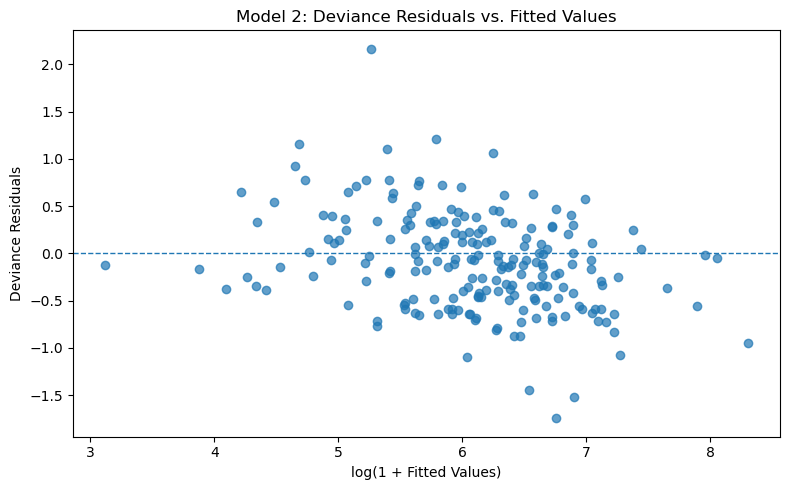

In [40]:
# Model 2 residual diagnostics
model2_fitted = nb_model2.fittedvalues
model2_deviance_resid = nb_model2.resid_deviance

plt.figure(figsize=(8, 5))
plt.scatter(np.log1p(model2_fitted), model2_deviance_resid, alpha=0.7)
plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("log(1 + Fitted Values)")
plt.ylabel("Deviance Residuals")
plt.title("Model 2: Deviance Residuals vs. Fitted Values")

plt.tight_layout()
plt.show()

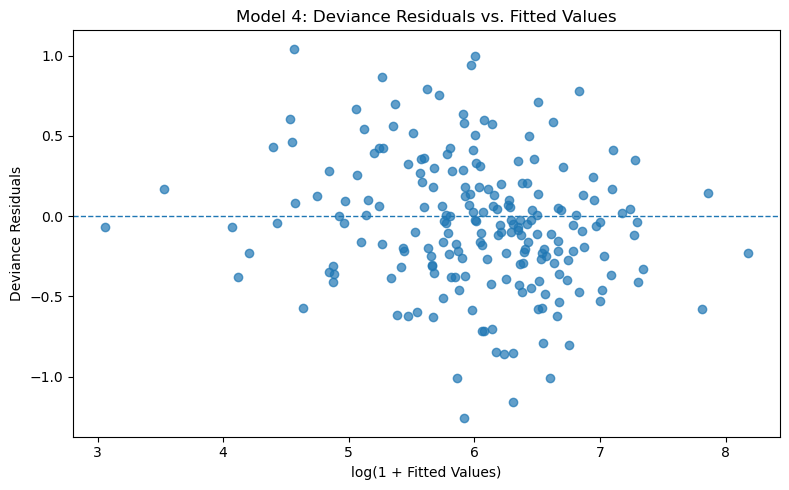

In [39]:
# Model 4 residual diagnostics
model4_fitted = nb_model4.fittedvalues
model4_deviance_resid = nb_model4.resid_deviance

plt.figure(figsize=(8, 5))
plt.scatter(np.log1p(model4_fitted), model4_deviance_resid, alpha=0.7)
plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("log(1 + Fitted Values)")
plt.ylabel("Deviance Residuals")
plt.title("Model 4: Deviance Residuals vs. Fitted Values")

plt.tight_layout()
plt.show()

The residual plots were shown using log-transformed fitted values because the fitted crash counts are highly skewed. The log transformation only changes the visualization scale and does not change the model estimates or residual values.

For both Model 2 and Model 4, most deviance residuals are centered around zero, suggesting that the Negative Binomial models capture the general crash-count pattern. However, the residuals are not perfectly randomly distributed, indicating that some tract-level heterogeneity remains unexplained. Model 4 shows a somewhat narrower residual range than Model 2, suggesting that the additional roadway design controls explain some additional variation, although residual structure remains.

The residual plots for Model 2 and Model 4 show that most deviance residuals are centered around zero, but the residuals are not perfectly randomly distributed. Several high-fitted census tracts show noticeable residual deviations, suggesting that the models may not fully capture all tract-level heterogeneity. Model 4 has a narrower residual range than Model 2, indicating some improvement after adding roadway design controls, but non-random residual structure remains. Therefore, the residual diagnostics support the need for additional checks such as Cook’s distance and VIF.

### 2. VIF / multicollinearity: Model 2 & Model 4

VIF is used to check whether predictors are highly correlated with each other, especially in Model 4, which includes many roadway design variables.

In [36]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def compute_vif(df, predictors):
    """
    Compute VIF for a list of predictors.
    Outcome variable and offset should Not be included.
    """

    X = (
        df[predictors]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .copy()
    )

    # Add constant for VIF
    X_const = sm.add_constant(X)

    vif_df = pd.DataFrame({
        "Variable": X_const.columns,
        "VIF": [
            variance_inflation_factor(X_const.values, i)
            for i in range(X_const.shape[1])
        ]
    })

    # Remove intercept from final table
    vif_df = vif_df[vif_df["Variable"] != "const"]

    return vif_df.sort_values("VIF", ascending=False)

In [37]:
model2_vars = [
    "road_density_km_per_km2",
    "signal_density_km2",
    "intersection_density_km2",
    "mean_aadt",
    "mean_iri",
    "mean_speedlimit_ob",
    "black_alone_share",
    "hispanic_share"
]

vif_model2 = compute_vif(tract_df, model2_vars)

vif_model2

,Variable,VIF
3,intersection_density_km2,220.547650
2,signal_density_km2,217.773308
1,road_density_km_per_km2,1.541352
7,black_alone_share,1.412724
8,hispanic_share,1.328943
6,mean_speedlimit_ob,1.179184
5,mean_iri,1.134162
4,mean_aadt,1.065930


In [38]:
model4_vars = [
    "road_density_km_per_km2",
    "signal_density_km2",
    "intersection_density_km2",
    "mean_aadt",
    "mean_iri",
    "mean_speedlimit_ob",
    "black_alone_share",
    "hispanic_share",
    "avg_travel_lanes",
    "avg_cross_section_width",
    "bike_lane_ratio",
    "bus_lane_ratio",
    "parking_lane_ratio",
    "sidewalk_ib_ratio",
    "sidewalk_ob_ratio",
    "high_speed_ratio",
    "vertical_deflection_ratio",
    "mean_pci_score"
]

vif_model4 = compute_vif(tract_df, model4_vars)

vif_model4

,Variable,VIF
2,signal_density_km2,266.334071
3,intersection_density_km2,261.846843
10,avg_cross_section_width,11.422690
9,avg_travel_lanes,9.037856
15,sidewalk_ob_ratio,8.271742
14,sidewalk_ib_ratio,7.529812
11,bike_lane_ratio,3.524952
7,black_alone_share,3.300683
17,vertical_deflection_ratio,3.115818
13,parking_lane_ratio,2.697807


VIF diagnostics show severe multicollinearity between `signal_density_km2` and `intersection_density_km2`. This suggests that these two variables capture highly overlapping roadway network characteristics, which is reasonable because traffic signals are often located at intersections. As a result, their individual coefficients should be interpreted with caution, since the model may have difficulty separating their independent effects.

Model 4 also shows moderate to high VIF values for several roadway design variables, such as roadway width, travel lanes, and sidewalk ratios. This indicates that some roadway design controls are conceptually and statistically related. Therefore, Model 4 is useful as a robustness check, but individual coefficients in Model 4 should not be over-interpreted.

Importantly, the key variables in the main model, including `road_density_km_per_km2`, `black_alone_share`, and `hispanic_share`, have low VIF values. This suggests that the main findings for roadway density and demographic context are not primarily driven by multicollinearity.

Because census tracts with many intersections often also contain more traffic signals, `signal_density_km2` and `intersection_density_km2` are highly correlated. This multicollinearity makes it difficult for the model to distinguish whether crash counts are independently associated with signal density or intersection density. For this reason, the next deliverable will introduce zoning and land use data to better capture the broader built-environment context.

Model 5 = Model 4 + zoning / land use built-environment controls

The model can be interpreted conceptually as:

```text
log(expected total_crashes)
= β0
+ roadway exposure variables
+ traffic / pavement / speed controls
+ Black and Hispanic population share
+ roadway design controls
+ zoning / land use controls
+ log_exposure_offset
```

## Robustness Checks

The robustness checks evaluate whether the main findings remain stable under alternative model specifications and diagnostic adjustments.

First, Model 4 is compared with Model 2. Model 4 adds additional roadway design controls, including travel lanes, roadway width, bike and bus lane coverage, parking lane coverage, sidewalk coverage, high-speed roadway share, traffic-calming features, and pavement condition. If road density and Black population share remain positive and statistically significant in Model 4, this supports the robustness of the main Model 2 findings.

Second, all models are estimated using HC3 robust standard errors. HC3 does not change the estimated coefficients or model fit statistics, but it makes statistical inference more robust to heteroskedasticity and influential observations by adjusting standard errors, z-statistics, p-values, and confidence intervals.

Third, an influential-observation sensitivity check can be conducted by removing census tracts with the highest Cook’s distance values and re-estimating Model 2. If road density and Black population share remain positive and statistically significant after removing these highly influential tracts, this suggests that the main findings are not driven by a small number of extreme observations.